In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

**Variables**

As a starting point, the data was downloaded as a CSV file from Oregon Department of Education (https://www.ode.state.or.us/data/ReportCard/Media). It has 1273 rows (entries), and 54 columns (variables), making there 68742 data points in total. Out of these data points, 18202 do not have a value associated with them, making about 26.5% of the dataset useless. The granularity of the data is relatively high given it is aggregated by individual school with primary key given by school ID.

For the most part, the variables in the data are formatted as strings, where much of which represent numerical values or ranges. This includes count values such as student enrollment, and range values like class size change value. Additionally, there are rows representing percentages, such as on-time graduation 2022-23. For both of these types of values, there are also special cases where a less than or greater sign is used to represent a "supression value". 

For example, in the case of the variable, students with disabilites, the documentation states "suppression occurs when the count is less than 10 students or percentages are less than 5 percent or greater than 95 percent. The suppression values are *, <5, and >95." This type of supression shematic is used for several other variables such as students experiencing poverty, languages spoken, regular attenders, etc. The other supression value mentioned in the quote, *, is also seen throughout the dataset with the same usage. However, there are also columns that use * to represent a truly unknown value, such as on-time graduation 2022-23. Lastly, there is another suppression schematic that is used only by the teachers column, where "<1" represents values less than 1.

Overall, there were minimal anomalies in the data, besides missing data, that needed to be addressed with data cleaning. The main examples are in some of the columns that represent percentages and use the <5% and >95% supression schematic. Cases included values such as <31% for a percentage, which did not have an explicit explanation in the documentation. 

In [2]:
# Read the dataset and put the data in a pandas DataFrame.
school_data_og = pd.read_csv("Oregon_schools_data.csv")
school_data_og

,District ID,District Name,School ID,School Name,Principal,Grades,School Type,County,Student Enrollment,Ever English Learners,...,On-Time Graduation 2022-23,On-Time Graduation Change from Last Year,On-Time Graduation Change Value,Oregon On-Time Graduation 2022-23 Average,Five-Year Completion 2022-23,Five-Year Completion Change from Last Year,Five-Year Completion Change Value,Oregon Five-Year Completion 2022-23 Average,College Going 2021-22,Oregon College Going 2021-22 Average
0,2063,Adel SD 21,498,Adel Elementary School,Lane Stratton,Grade(s) K-8,E,Lake,11.0,*,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2113,Adrian SD 61,707,Adrian Elementary School,Nick Ketterling,Grade(s) K-8,E,Malheur,194.0,9%,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2113,Adrian SD 61,708,Adrian High School,Bill Wortman,Grade(s) 9-12,H,Malheur,88.0,22%,...,94%,Decrease,1%,81%,100%,No Change,NaN,87%,50%,53%
3,1899,Alsea SD 7J,17,Alsea Charter School,Bart Rothenberger,Grade(s) K-12,H,Benton,252.0,*,...,40%,Decrease,2%,81%,46%,Decrease,14%,87%,15%,53%
4,2252,Amity SD 4J,1208,Amity Elementary School,Jessica Rojas,Grade(s) K-5,E,Yamhill,313.0,10%,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,2251,Yamhill Carlton SD 1,1213,Yamhill Carlton Elementary School,Amanda Dallas,Grade(s) K-3,E,Yamhill,289.0,<5%,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1269,2251,Yamhill Carlton SD 1,1238,Yamhill Carlton High School,Tanner Smith,Grade(s) 9-12,H,Yamhill,268.0,6%,...,85%,Increase,19%,81%,75%,Decrease,15%,87%,52%,53%
1270,2251,Yamhill Carlton SD 1,4564,Yamhill Carlton Intermediate School,Matt Wiles,Grade(s) 4-8,M,Yamhill,353.0,6%,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1271,1997,Yoncalla SD 32,299,Yoncalla Elementary School,Brian Berry,Grade(s) K-8,E,Douglas,187.0,*,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Identify the data types for each column in the dataset.
print(school_data_og.dtypes)

District ID                                      int64
District Name                                      str
School ID                                        int64
School Name                                        str
Principal                                          str
Grades                                             str
School Type                                        str
County                                             str
Student Enrollment                             float64
Ever English Learners                              str
Languages Spoken                                   str
Students with Disabilities                         str
Students Experiencing Poverty                      str
Required Childhood Vaccinations                    str
Teachers                                           str
Educational Assistants                             str
Counselors/Psychologists/Social Workers            str
Average Teacher Retention Rate                     str
Experience

In [4]:
# Calculate the total number and proportion of Null values in the dataset
total_na = school_data_og.isna().sum().values.sum()
print(f"Total Null: {total_na}")
print(f"Proportion Null: {total_na / school_data_og.size} ")

Total Null: 18202
Proportion Null: 0.26478717523493644 


**Cleaning**

For cleaning, the majority of the work is properly formatting numerical values, which is a little tedious for percentages and percentage ranges. For values such as "42%", all that needs to be in done is strip the string of "%", convert it to a float data type and divide by 100 to represent a proportion. In terms of representing the strings "<5%" and ">95%" in a effective way, I chose to convert each value to 0.025 and 0.975 respectively. This allows me to have a dataset with a larger sample size that is easily convertible to a version that doesn't include suppression values, which will be useful for comparing how the inclusion and exclusion of these data points affects relationships among variables. For the case of "<1" in the teachers column, I chose to replace those values with 0.5 based on the same raionale.

Additionally, because in both use cases of * represent the same ide of missing data, regardless if it has a true value in the world, I chose to change all instances of * to the string "None". I also did the same for values of "-1", which are unique to the average teacher retention rate column but also represent missing data. the The "None" string was used instead of a Null value such as None or np.nan as a workaround for several eorrors involving a "non iterable float or NoneType". 


In [5]:
# Initialize static variables that will be used throughout the data exploration and create a copy of the original DataFrame in order to leave a unedited version for later comparison.
school_data_og_cols = school_data_og.columns
school_counties = school_data_og["County"].unique()
school_data = school_data_og.fillna("None").copy() # Workaround for string method errors with Null value
school_data

,District ID,District Name,School ID,School Name,Principal,Grades,School Type,County,Student Enrollment,Ever English Learners,...,On-Time Graduation 2022-23,On-Time Graduation Change from Last Year,On-Time Graduation Change Value,Oregon On-Time Graduation 2022-23 Average,Five-Year Completion 2022-23,Five-Year Completion Change from Last Year,Five-Year Completion Change Value,Oregon Five-Year Completion 2022-23 Average,College Going 2021-22,Oregon College Going 2021-22 Average
0,2063,Adel SD 21,498,Adel Elementary School,Lane Stratton,Grade(s) K-8,E,Lake,11.0,*,...,None,None,None,None,None,None,None,None,None,None
1,2113,Adrian SD 61,707,Adrian Elementary School,Nick Ketterling,Grade(s) K-8,E,Malheur,194.0,9%,...,None,None,None,None,None,None,None,None,None,None
2,2113,Adrian SD 61,708,Adrian High School,Bill Wortman,Grade(s) 9-12,H,Malheur,88.0,22%,...,94%,Decrease,1%,81%,100%,No Change,None,87%,50%,53%
3,1899,Alsea SD 7J,17,Alsea Charter School,Bart Rothenberger,Grade(s) K-12,H,Benton,252.0,*,...,40%,Decrease,2%,81%,46%,Decrease,14%,87%,15%,53%
4,2252,Amity SD 4J,1208,Amity Elementary School,Jessica Rojas,Grade(s) K-5,E,Yamhill,313.0,10%,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,2251,Yamhill Carlton SD 1,1213,Yamhill Carlton Elementary School,Amanda Dallas,Grade(s) K-3,E,Yamhill,289.0,<5%,...,None,None,None,None,None,None,None,None,None,None
1269,2251,Yamhill Carlton SD 1,1238,Yamhill Carlton High School,Tanner Smith,Grade(s) 9-12,H,Yamhill,268.0,6%,...,85%,Increase,19%,81%,75%,Decrease,15%,87%,52%,53%
1270,2251,Yamhill Carlton SD 1,4564,Yamhill Carlton Intermediate School,Matt Wiles,Grade(s) 4-8,M,Yamhill,353.0,6%,...,None,None,None,None,None,None,None,None,None,None
1271,1997,Yoncalla SD 32,299,Yoncalla Elementary School,Brian Berry,Grade(s) K-8,E,Douglas,187.0,*,...,None,None,None,None,None,None,None,None,None,None


In [6]:
"""
* = NO DATA:
    Languages Spoken
    Class Size
    Five-Year Completion 2022-23
    On-Time Graduation 2022-23
-1 = NO DATA:
    Average Teacher Retention Rate
"""

# Replace all instances of "*" or "-1" in the school_data DataFrame with "None" (only occur in the columns listed below).
for col in ["Languages Spoken", "Class Size", "Five-Year Completion 2022-23", "On-Time Graduation 2022-23", "Average Teacher Retention Rate"]:
    school_data[col] = school_data[col].apply(lambda x: "None" if (x == "*") or (x == "-1") else x)
school_data


,District ID,District Name,School ID,School Name,Principal,Grades,School Type,County,Student Enrollment,Ever English Learners,...,On-Time Graduation 2022-23,On-Time Graduation Change from Last Year,On-Time Graduation Change Value,Oregon On-Time Graduation 2022-23 Average,Five-Year Completion 2022-23,Five-Year Completion Change from Last Year,Five-Year Completion Change Value,Oregon Five-Year Completion 2022-23 Average,College Going 2021-22,Oregon College Going 2021-22 Average
0,2063,Adel SD 21,498,Adel Elementary School,Lane Stratton,Grade(s) K-8,E,Lake,11.0,*,...,None,None,None,None,None,None,None,None,None,None
1,2113,Adrian SD 61,707,Adrian Elementary School,Nick Ketterling,Grade(s) K-8,E,Malheur,194.0,9%,...,None,None,None,None,None,None,None,None,None,None
2,2113,Adrian SD 61,708,Adrian High School,Bill Wortman,Grade(s) 9-12,H,Malheur,88.0,22%,...,94%,Decrease,1%,81%,100%,No Change,None,87%,50%,53%
3,1899,Alsea SD 7J,17,Alsea Charter School,Bart Rothenberger,Grade(s) K-12,H,Benton,252.0,*,...,40%,Decrease,2%,81%,46%,Decrease,14%,87%,15%,53%
4,2252,Amity SD 4J,1208,Amity Elementary School,Jessica Rojas,Grade(s) K-5,E,Yamhill,313.0,10%,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,2251,Yamhill Carlton SD 1,1213,Yamhill Carlton Elementary School,Amanda Dallas,Grade(s) K-3,E,Yamhill,289.0,<5%,...,None,None,None,None,None,None,None,None,None,None
1269,2251,Yamhill Carlton SD 1,1238,Yamhill Carlton High School,Tanner Smith,Grade(s) 9-12,H,Yamhill,268.0,6%,...,85%,Increase,19%,81%,75%,Decrease,15%,87%,52%,53%
1270,2251,Yamhill Carlton SD 1,4564,Yamhill Carlton Intermediate School,Matt Wiles,Grade(s) 4-8,M,Yamhill,353.0,6%,...,None,None,None,None,None,None,None,None,None,None
1271,1997,Yoncalla SD 32,299,Yoncalla Elementary School,Brian Berry,Grade(s) K-8,E,Douglas,187.0,*,...,None,None,None,None,None,None,None,None,None,None


In [7]:
# Function to use properly convert a series of strings to numerical percentage values or "None" based on the formatting of their column. 
def clean_percentage(x):
    if (x == "None") or (x == "*") or (x == "-1"):
        return "None"
    elif x == "<5%":
        return 0.025 # "<5%" => 0.025
    elif x == ">95%":
        return 0.975 # ">95%" => 0.975
    elif ("<" in x) or (">" in x):
        return float(x.strip(">").strip("<").strip("%"))
    else:
        return float(x.strip("%")) / 100
    

In [8]:
# Apply the clean_percentage function to all the columns in the school_data DataFrame that use a percentage formatting.
percent_cols = school_data.columns[school_data.astype(str).apply(lambda col: col.str.contains('%', na=False)).any()].to_list()
for col in percent_cols:
    school_data[col] = school_data[col].apply(clean_percentage)
    new_col_name = col + " (Proportion)"
    school_data = school_data.rename(columns={col: new_col_name})
school_data

,District ID,District Name,School ID,School Name,Principal,Grades,School Type,County,Student Enrollment,Ever English Learners (Proportion),...,On-Time Graduation 2022-23 (Proportion),On-Time Graduation Change from Last Year,On-Time Graduation Change Value (Proportion),Oregon On-Time Graduation 2022-23 Average (Proportion),Five-Year Completion 2022-23 (Proportion),Five-Year Completion Change from Last Year,Five-Year Completion Change Value (Proportion),Oregon Five-Year Completion 2022-23 Average (Proportion),College Going 2021-22 (Proportion),Oregon College Going 2021-22 Average (Proportion)
0,2063,Adel SD 21,498,Adel Elementary School,Lane Stratton,Grade(s) K-8,E,Lake,11.0,None,...,None,None,None,None,None,None,None,None,None,None
1,2113,Adrian SD 61,707,Adrian Elementary School,Nick Ketterling,Grade(s) K-8,E,Malheur,194.0,0.09,...,None,None,None,None,None,None,None,None,None,None
2,2113,Adrian SD 61,708,Adrian High School,Bill Wortman,Grade(s) 9-12,H,Malheur,88.0,0.22,...,0.94,Decrease,0.01,0.81,1.0,No Change,None,0.87,0.5,0.53
3,1899,Alsea SD 7J,17,Alsea Charter School,Bart Rothenberger,Grade(s) K-12,H,Benton,252.0,None,...,0.4,Decrease,0.02,0.81,0.46,Decrease,0.14,0.87,0.15,0.53
4,2252,Amity SD 4J,1208,Amity Elementary School,Jessica Rojas,Grade(s) K-5,E,Yamhill,313.0,0.1,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,2251,Yamhill Carlton SD 1,1213,Yamhill Carlton Elementary School,Amanda Dallas,Grade(s) K-3,E,Yamhill,289.0,0.025,...,None,None,None,None,None,None,None,None,None,None
1269,2251,Yamhill Carlton SD 1,1238,Yamhill Carlton High School,Tanner Smith,Grade(s) 9-12,H,Yamhill,268.0,0.06,...,0.85,Increase,0.19,0.81,0.75,Decrease,0.15,0.87,0.52,0.53
1270,2251,Yamhill Carlton SD 1,4564,Yamhill Carlton Intermediate School,Matt Wiles,Grade(s) 4-8,M,Yamhill,353.0,0.06,...,None,None,None,None,None,None,None,None,None,None
1271,1997,Yoncalla SD 32,299,Yoncalla Elementary School,Brian Berry,Grade(s) K-8,E,Douglas,187.0,None,...,None,None,None,None,None,None,None,None,None,None


In [9]:
# Create a list of column names that do not use percentage formatting, and use that list to create two new lists: numeric and non-numeric column names.
non_percent_cols = school_data_og_cols[~school_data_og_cols.isin(percent_cols)].to_list()
non_percent_school_data = school_data[non_percent_cols]
non_numeric_cols = [col for col in non_percent_cols if pd.to_numeric(non_percent_school_data[col], errors='coerce').isna().all()]
numeric_cols = [col for col in non_percent_cols if col not in non_numeric_cols][2:]
numeric_cols


['Student Enrollment',
 'Languages Spoken',
 'Teachers',
 'Educational Assistants',
 'Counselors/Psychologists/Social Workers',
 'Class Size',
 'Class Size Change Value',
 'Oregon Class Size Average']

In [10]:
non_numeric_cols

['District Name',
 'School Name',
 'Principal',
 'Grades',
 'School Type',
 'County',
 'Same Principal in the Last 3 Years',
 'Class Size Change from Last Year',
 'Regular Attenders Change from Last Year',
 'ELA Change from Last Year',
 'Mathematics Change from Last Year',
 'Science Change from Last Year',
 'On-Track to Graduate Change from Last Year',
 'On-Time Graduation Change from Last Year',
 'Five-Year Completion Change from Last Year']

In [11]:
# Function to use properly convert a series of strings to numerical values (float) or "None" based on the formatting of their column.
def clean_numeric(x):
    if x == "None":
        return x
    elif x == "<1":
        return 0.5 # "<1" => 0.5 
    else:
        return float(x)

In [12]:
# Apply the clean_numeric function to all the columns in the school_data DataFrame that use a numeric formatting.
for col in numeric_cols:
    school_data[col] = school_data[col].apply(clean_numeric)
school_data

,District ID,District Name,School ID,School Name,Principal,Grades,School Type,County,Student Enrollment,Ever English Learners (Proportion),...,On-Time Graduation 2022-23 (Proportion),On-Time Graduation Change from Last Year,On-Time Graduation Change Value (Proportion),Oregon On-Time Graduation 2022-23 Average (Proportion),Five-Year Completion 2022-23 (Proportion),Five-Year Completion Change from Last Year,Five-Year Completion Change Value (Proportion),Oregon Five-Year Completion 2022-23 Average (Proportion),College Going 2021-22 (Proportion),Oregon College Going 2021-22 Average (Proportion)
0,2063,Adel SD 21,498,Adel Elementary School,Lane Stratton,Grade(s) K-8,E,Lake,11.0,None,...,None,None,None,None,None,None,None,None,None,None
1,2113,Adrian SD 61,707,Adrian Elementary School,Nick Ketterling,Grade(s) K-8,E,Malheur,194.0,0.09,...,None,None,None,None,None,None,None,None,None,None
2,2113,Adrian SD 61,708,Adrian High School,Bill Wortman,Grade(s) 9-12,H,Malheur,88.0,0.22,...,0.94,Decrease,0.01,0.81,1.0,No Change,None,0.87,0.5,0.53
3,1899,Alsea SD 7J,17,Alsea Charter School,Bart Rothenberger,Grade(s) K-12,H,Benton,252.0,None,...,0.4,Decrease,0.02,0.81,0.46,Decrease,0.14,0.87,0.15,0.53
4,2252,Amity SD 4J,1208,Amity Elementary School,Jessica Rojas,Grade(s) K-5,E,Yamhill,313.0,0.1,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,2251,Yamhill Carlton SD 1,1213,Yamhill Carlton Elementary School,Amanda Dallas,Grade(s) K-3,E,Yamhill,289.0,0.025,...,None,None,None,None,None,None,None,None,None,None
1269,2251,Yamhill Carlton SD 1,1238,Yamhill Carlton High School,Tanner Smith,Grade(s) 9-12,H,Yamhill,268.0,0.06,...,0.85,Increase,0.19,0.81,0.75,Decrease,0.15,0.87,0.52,0.53
1270,2251,Yamhill Carlton SD 1,4564,Yamhill Carlton Intermediate School,Matt Wiles,Grade(s) 4-8,M,Yamhill,353.0,0.06,...,None,None,None,None,None,None,None,None,None,None
1271,1997,Yoncalla SD 32,299,Yoncalla Elementary School,Brian Berry,Grade(s) K-8,E,Douglas,187.0,None,...,None,None,None,None,None,None,None,None,None,None


In [13]:
# Replace all values of "None" in the school_data DataFrame with None.
school_data = school_data.replace("None", np.nan)

In [14]:
school_data

,District ID,District Name,School ID,School Name,Principal,Grades,School Type,County,Student Enrollment,Ever English Learners (Proportion),...,On-Time Graduation 2022-23 (Proportion),On-Time Graduation Change from Last Year,On-Time Graduation Change Value (Proportion),Oregon On-Time Graduation 2022-23 Average (Proportion),Five-Year Completion 2022-23 (Proportion),Five-Year Completion Change from Last Year,Five-Year Completion Change Value (Proportion),Oregon Five-Year Completion 2022-23 Average (Proportion),College Going 2021-22 (Proportion),Oregon College Going 2021-22 Average (Proportion)
0,2063,Adel SD 21,498,Adel Elementary School,Lane Stratton,Grade(s) K-8,E,Lake,11.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2113,Adrian SD 61,707,Adrian Elementary School,Nick Ketterling,Grade(s) K-8,E,Malheur,194.0,0.09,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2113,Adrian SD 61,708,Adrian High School,Bill Wortman,Grade(s) 9-12,H,Malheur,88.0,0.22,...,0.94,Decrease,0.01,0.81,1.0,No Change,NaN,0.87,0.5,0.53
3,1899,Alsea SD 7J,17,Alsea Charter School,Bart Rothenberger,Grade(s) K-12,H,Benton,252.0,NaN,...,0.4,Decrease,0.02,0.81,0.46,Decrease,0.14,0.87,0.15,0.53
4,2252,Amity SD 4J,1208,Amity Elementary School,Jessica Rojas,Grade(s) K-5,E,Yamhill,313.0,0.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,2251,Yamhill Carlton SD 1,1213,Yamhill Carlton Elementary School,Amanda Dallas,Grade(s) K-3,E,Yamhill,289.0,0.025,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1269,2251,Yamhill Carlton SD 1,1238,Yamhill Carlton High School,Tanner Smith,Grade(s) 9-12,H,Yamhill,268.0,0.06,...,0.85,Increase,0.19,0.81,0.75,Decrease,0.15,0.87,0.52,0.53
1270,2251,Yamhill Carlton SD 1,4564,Yamhill Carlton Intermediate School,Matt Wiles,Grade(s) 4-8,M,Yamhill,353.0,0.06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1271,1997,Yoncalla SD 32,299,Yoncalla Elementary School,Brian Berry,Grade(s) K-8,E,Douglas,187.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Associations and Structure**

Because the majority of the data used for the analysis is quantitative, associations and structure are revealed by making scatter plots of numerical variables. Many of these relationships have no significant linear assocation, while several others do, as is seen in the pair plot for all the quantitative variables. To find these variable pairs with a strong linear association, the Pearson Correlation Coefficient is calculated for every variable pair and the top three highest (positive) and lowest (negative) are considered the most strongly associated. Additionally, because county is an important geograpical indicator, the data can also be aggregated at the county level to reveal patterns by county in both mean variable values and associations among the the most strongly associated variables of the entire dataset. 

In [15]:
# List of variables whose relationship to other variables may provide insight about the structure and associations within the data.
variables_of_interest = [
    'Ever English Learners (Proportion)', 
    'Languages Spoken',
    'Students with Disabilities (Proportion)',
    'Students Experiencing Poverty (Proportion)',
    'Required Childhood Vaccinations (Proportion)', 
    'Teachers',
    'Educational Assistants', 
    'Counselors/Psychologists/Social Workers',
    'Average Teacher Retention Rate (Proportion)',
    'Experienced Teachers (Proportion)',
    'Class Size',
    'Regular Attenders (Proportion)',
    'English Language Arts (Proportion)', 
    'Mathematics (Proportion)', 
    'Science (Proportion)',
    'On-Track to Graduate (Proportion)',
    'On-Time Graduation 2022-23 (Proportion)',
    'Five-Year Completion 2022-23 (Proportion)',
    'College Going 2021-22 (Proportion)',
    ]

In [16]:
# Create a new DataFrame representing the quantatative variables of interest in the school_data DataFrame.
quantitative_cols = school_data[variables_of_interest]
quantitative_cols

,Ever English Learners (Proportion),Languages Spoken,Students with Disabilities (Proportion),Students Experiencing Poverty (Proportion),Required Childhood Vaccinations (Proportion),Teachers,Educational Assistants,Counselors/Psychologists/Social Workers,Average Teacher Retention Rate (Proportion),Experienced Teachers (Proportion),Class Size,Regular Attenders (Proportion),English Language Arts (Proportion),Mathematics (Proportion),Science (Proportion),On-Track to Graduate (Proportion),On-Time Graduation 2022-23 (Proportion),Five-Year Completion 2022-23 (Proportion),College Going 2021-22 (Proportion)
0,NaN,2.0,NaN,NaN,0.91,2.0,0.0,0.0,1.0,1.0,11.0,0.64,0.46,0.73,NaN,NaN,NaN,NaN,NaN
1,0.09,3.0,0.11,0.33,0.93,13.0,8.0,0.0,0.88,0.77,22.0,0.88,0.75,0.64,0.61,NaN,NaN,NaN,NaN
2,0.22,5.0,0.13,0.22,0.92,9.0,0.0,1.0,0.88,0.5,10.0,0.77,NaN,NaN,NaN,0.975,0.94,1.0,0.5
3,NaN,7.0,0.17,0.5,0.88,19.0,1.0,0.0,0.72,0.53,13.0,0.68,NaN,NaN,NaN,0.975,0.4,0.46,0.15
4,0.1,3.0,0.12,0.33,0.89,18.0,8.0,0.0,0.88,0.7,20.0,0.72,0.29,0.23,0.13,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,0.025,10.0,0.13,0.22,0.87,18.0,11.0,1.0,0.66,0.53,22.0,0.7,0.43,0.43,NaN,NaN,NaN,NaN,NaN
1269,0.06,4.0,0.16,0.19,0.94,18.0,5.0,1.0,0.92,0.68,17.0,0.68,NaN,NaN,NaN,0.92,0.85,0.75,0.52
1270,0.06,7.0,0.21,0.26,0.86,19.0,15.0,1.0,0.73,0.27,21.5,0.73,0.36,0.26,0.19,NaN,NaN,NaN,NaN
1271,NaN,1.0,0.21,0.47,0.88,11.0,5.0,0.0,0.76,0.7,19.5,0.64,0.42,0.2,0.19,NaN,NaN,NaN,NaN


In [17]:
# Create a new DataFrame representing the quantatative variables of interest in the school_data DataFrame that also includes county name. Group the data by county to give the mean value for each quantatative variable.
quantitative_cols_county = school_data[["County"] + variables_of_interest]
quantitative_cols_county = quantitative_cols_county.groupby("County").mean().reset_index()
quantitative_cols_county

,County,Ever English Learners (Proportion),Languages Spoken,Students with Disabilities (Proportion),Students Experiencing Poverty (Proportion),Required Childhood Vaccinations (Proportion),Teachers,Educational Assistants,Counselors/Psychologists/Social Workers,Average Teacher Retention Rate (Proportion),Experienced Teachers (Proportion),Class Size,Regular Attenders (Proportion),English Language Arts (Proportion),Mathematics (Proportion),Science (Proportion),On-Track to Graduate (Proportion),On-Time Graduation 2022-23 (Proportion),Five-Year Completion 2022-23 (Proportion),College Going 2021-22 (Proportion)
0,Baker,0.03125,3.142857,0.17125,0.435385,0.805714,16.233333,4.033333,1.600000,0.73,0.842308,16.730769,0.589643,0.4575,0.3725,0.41,0.801,0.701429,0.888571,0.38
1,Benton,0.145,11.16,0.14125,0.265417,0.9184,19.200000,8.420000,1.080000,0.8596,0.7528,21.04,0.6864,0.544118,0.444118,0.45125,0.859167,0.748571,0.842857,0.59
2,Clackamas,0.153281,12.963964,0.169369,0.227064,0.903063,25.554054,7.792793,1.585586,0.837706,0.826486,23.431818,0.702432,0.498214,0.419048,0.34631,0.8325,0.822,0.878333,0.512917
3,Clatsop,0.141,4.866667,0.178462,0.335333,0.841333,20.933333,10.600000,1.533333,0.836429,0.791429,18.2,0.673333,0.372222,0.273333,0.228571,0.86875,0.803333,0.882,0.544
4,Columbia,0.0455,4.26087,0.181905,0.310909,0.815217,17.130435,6.847826,0.934783,0.820435,0.705652,19.928571,0.643261,0.431333,0.300667,0.231818,0.803,0.7125,0.81625,0.356875
5,Coos,0.040833,4.346154,0.171818,0.433846,0.909615,18.076923,6.326923,0.538462,0.800769,0.774231,18.673077,0.598077,0.38,0.304,0.262273,0.70375,0.694,0.742,0.33625
6,Crook,0.09125,5.0,0.164286,0.337143,0.92125,22.875000,7.500000,0.875000,0.7725,0.68375,18.8125,0.66,0.445,0.408333,0.324,0.95,0.97,0.93,0.27
7,Curry,0.051667,3.714286,0.155,0.447143,0.888571,15.714286,5.928571,0.714286,0.758571,0.692857,17.571429,0.665714,0.335,0.2375,0.2475,0.861667,0.593333,0.833333,0.57
8,Deschutes,0.112361,5.576923,0.1364,0.254412,0.869608,24.557692,6.644231,2.211538,0.832308,0.868077,23.221154,0.678627,0.508,0.42425,0.358846,0.894091,0.859,0.881,0.512
9,Douglas,0.03,3.574468,0.181778,0.445435,0.88383,18.595745,8.170213,1.063830,0.817826,0.701957,17.734043,0.655978,0.367586,0.265862,0.241346,0.82375,0.711667,0.797778,0.38625


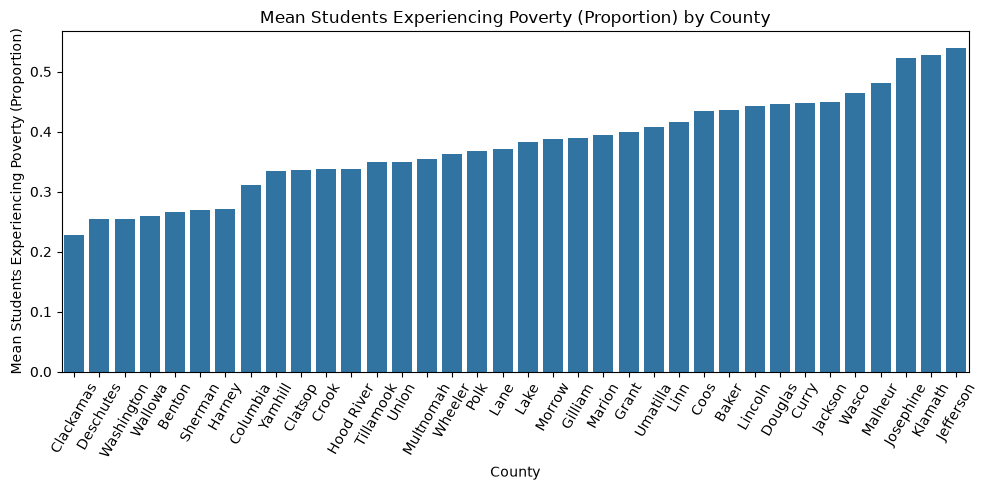

In [18]:
# Create a bar plot for a chosen variable in the newly created DataFrame where the x values are counties and the y values are variable values. Arrange the scatter plot so y values increase left to right.
variable = "Students Experiencing Poverty (Proportion)"
col_data = quantitative_cols_county[["County", variable]].sort_values(by=variable)
plt.figure(figsize=(10,5))
sns.barplot(x=col_data["County"], y=col_data[variable])
plt.title(f"Mean {variable} by County")
plt.xticks(rotation=60)
plt.xlabel("County")
plt.ylabel(f"Mean {variable}")
plt.tight_layout()
plt.show()

In [19]:
# Summarize statistics for all the quantitative variables of interest.
quantitative_cols.describe()

,Teachers,Educational Assistants,Counselors/Psychologists/Social Workers
count,1273.000000,1273.000000,1273.000000
mean,23.487431,8.597408,1.508641
std,17.014937,6.437711,1.720302
min,0.000000,0.000000,0.000000
25%,14.000000,4.000000,0.500000
50%,21.000000,8.000000,1.000000
75%,27.000000,13.000000,2.000000
max,137.000000,42.000000,14.000000


In [20]:
# Create a scatter plot for every relationship amongst the quantitative variables of interest.
pairplot = False # CHANGE TO DISPLAY
if pairplot:
    sns.pairplot(quantitative_cols) 

In [21]:
# Calculate the Pearson Correlation Coefficient for every relationship amongst the quantitative variables of interest.
r_data = quantitative_cols.corr()
r_data = r_data.replace(1.0, np.nan)
r_data

,Ever English Learners (Proportion),Languages Spoken,Students with Disabilities (Proportion),Students Experiencing Poverty (Proportion),Required Childhood Vaccinations (Proportion),Teachers,Educational Assistants,Counselors/Psychologists/Social Workers,Average Teacher Retention Rate (Proportion),Experienced Teachers (Proportion),Class Size,Regular Attenders (Proportion),English Language Arts (Proportion),Mathematics (Proportion),Science (Proportion),On-Track to Graduate (Proportion),On-Time Graduation 2022-23 (Proportion),Five-Year Completion 2022-23 (Proportion),College Going 2021-22 (Proportion)
Ever English Learners (Proportion),NaN,0.261534,-0.055152,0.410087,0.113822,0.129015,0.205603,0.167525,-0.040747,-0.125919,-0.015510,-0.213303,-0.537082,-0.479025,-0.482667,0.009684,0.005100,0.035348,-0.081852
Languages Spoken,0.261534,NaN,-0.206674,-0.242813,0.137611,0.646963,0.260164,0.644972,0.134257,0.151455,0.298654,-0.012740,0.098028,0.114699,0.060537,0.095537,0.222021,0.176689,0.489221
Students with Disabilities (Proportion),-0.055152,-0.206674,NaN,0.352082,0.076359,-0.222425,0.078620,-0.156847,-0.055976,-0.051178,-0.124567,-0.266663,-0.274986,-0.234833,-0.238800,-0.377091,-0.407894,-0.343907,-0.393853
Students Experiencing Poverty (Proportion),0.410087,-0.242813,0.352082,NaN,-0.012708,-0.174573,0.167292,-0.190780,-0.221446,-0.308274,-0.182249,-0.428499,-0.772453,-0.723231,-0.687706,-0.478391,-0.543353,-0.522297,-0.669895
Required Childhood Vaccinations (Proportion),0.113822,0.137611,0.076359,-0.012708,NaN,0.173091,0.211012,0.129357,0.079663,-0.045099,0.076547,0.047416,-0.054342,0.007453,-0.071906,-0.006747,0.158224,0.068453,0.041711
Teachers,0.129015,0.646963,-0.222425,-0.174573,0.173091,NaN,0.518152,0.833872,0.203349,0.082607,0.250470,-0.088766,-0.116234,-0.092988,-0.154983,0.120928,0.299899,0.239890,0.458760
Educational Assistants,0.205603,0.260164,0.078620,0.167292,0.211012,0.518152,NaN,0.328503,0.148242,-0.009191,0.186387,0.017892,-0.290124,-0.196278,-0.232466,0.102062,0.208938,0.183214,0.269779
Counselors/Psychologists/Social Workers,0.167525,0.644972,-0.156847,-0.190780,0.129357,0.833872,0.328503,NaN,0.160138,0.151807,0.217476,-0.176632,-0.042242,-0.037605,-0.073650,0.061612,0.207072,0.155980,0.412690
Average Teacher Retention Rate (Proportion),-0.040747,0.134257,-0.055976,-0.221446,0.079663,0.203349,0.148242,0.160138,NaN,0.343038,0.033538,0.168427,0.169645,0.177983,0.139157,0.288328,0.269926,0.183877,0.338201
Experienced Teachers (Proportion),-0.125919,0.151455,-0.051178,-0.308274,-0.045099,0.082607,-0.009191,0.151807,0.343038,NaN,0.029824,0.125434,0.317364,0.331969,0.291236,0.004200,0.034936,-0.012693,0.169017


In [22]:
r_data.unstack().dropna().sort_values(ascending=False).reset_index()

,level_0,level_1,0
0,English Language Arts (Proportion),Mathematics (Proportion),0.912777
1,Mathematics (Proportion),English Language Arts (Proportion),0.912777
2,Science (Proportion),English Language Arts (Proportion),0.867070
3,English Language Arts (Proportion),Science (Proportion),0.867070
4,Mathematics (Proportion),Science (Proportion),0.854578
...,...,...,...
313,Science (Proportion),Students Experiencing Poverty (Proportion),-0.687706
314,Students Experiencing Poverty (Proportion),Mathematics (Proportion),-0.723231
315,Mathematics (Proportion),Students Experiencing Poverty (Proportion),-0.723231
316,English Language Arts (Proportion),Students Experiencing Poverty (Proportion),-0.772453


In [23]:
# Sort the Pearson Correlation Coefficients for every relationship amongst the quantitative variables of interest to find the variable pairs with the strongest linear association.
r_data_pairs = r_data.unstack().dropna().sort_values(ascending=False).reset_index().rename(columns={"level_0": "x", "level_1": "y", 0: "r"})
r_data_pairs = r_data_pairs.drop_duplicates(subset="r")
r_data_pairs.head(10)

,x,y,r
0,English Language Arts (Proportion),Mathematics (Proportion),0.912777
2,Science (Proportion),English Language Arts (Proportion),0.867070
4,Mathematics (Proportion),Science (Proportion),0.854578
6,Counselors/Psychologists/Social Workers,Teachers,0.833872
8,On-Time Graduation 2022-23 (Proportion),Five-Year Completion 2022-23 (Proportion),0.727060
10,Languages Spoken,Teachers,0.646963
12,Counselors/Psychologists/Social Workers,Languages Spoken,0.644972
14,On-Time Graduation 2022-23 (Proportion),On-Track to Graduate (Proportion),0.642041
16,Mathematics (Proportion),Regular Attenders (Proportion),0.630511
18,Regular Attenders (Proportion),English Language Arts (Proportion),0.619282


In [24]:
r_data_pairs.tail(10)

,x,y,r
298,Students Experiencing Poverty (Proportion),On-Track to Graduate (Proportion),-0.478391
300,Mathematics (Proportion),Ever English Learners (Proportion),-0.479025
302,Ever English Learners (Proportion),Science (Proportion),-0.482667
304,Students Experiencing Poverty (Proportion),Five-Year Completion 2022-23 (Proportion),-0.522297
306,English Language Arts (Proportion),Ever English Learners (Proportion),-0.537082
308,On-Time Graduation 2022-23 (Proportion),Students Experiencing Poverty (Proportion),-0.543353
310,College Going 2021-22 (Proportion),Students Experiencing Poverty (Proportion),-0.669895
312,Students Experiencing Poverty (Proportion),Science (Proportion),-0.687706
314,Students Experiencing Poverty (Proportion),Mathematics (Proportion),-0.723231
316,English Language Arts (Proportion),Students Experiencing Poverty (Proportion),-0.772453


In [25]:
r_data_pairs.tail(10)["r"][312] - r_data_pairs.tail(10)["r"][316]

np.float64(0.08474760096838796)

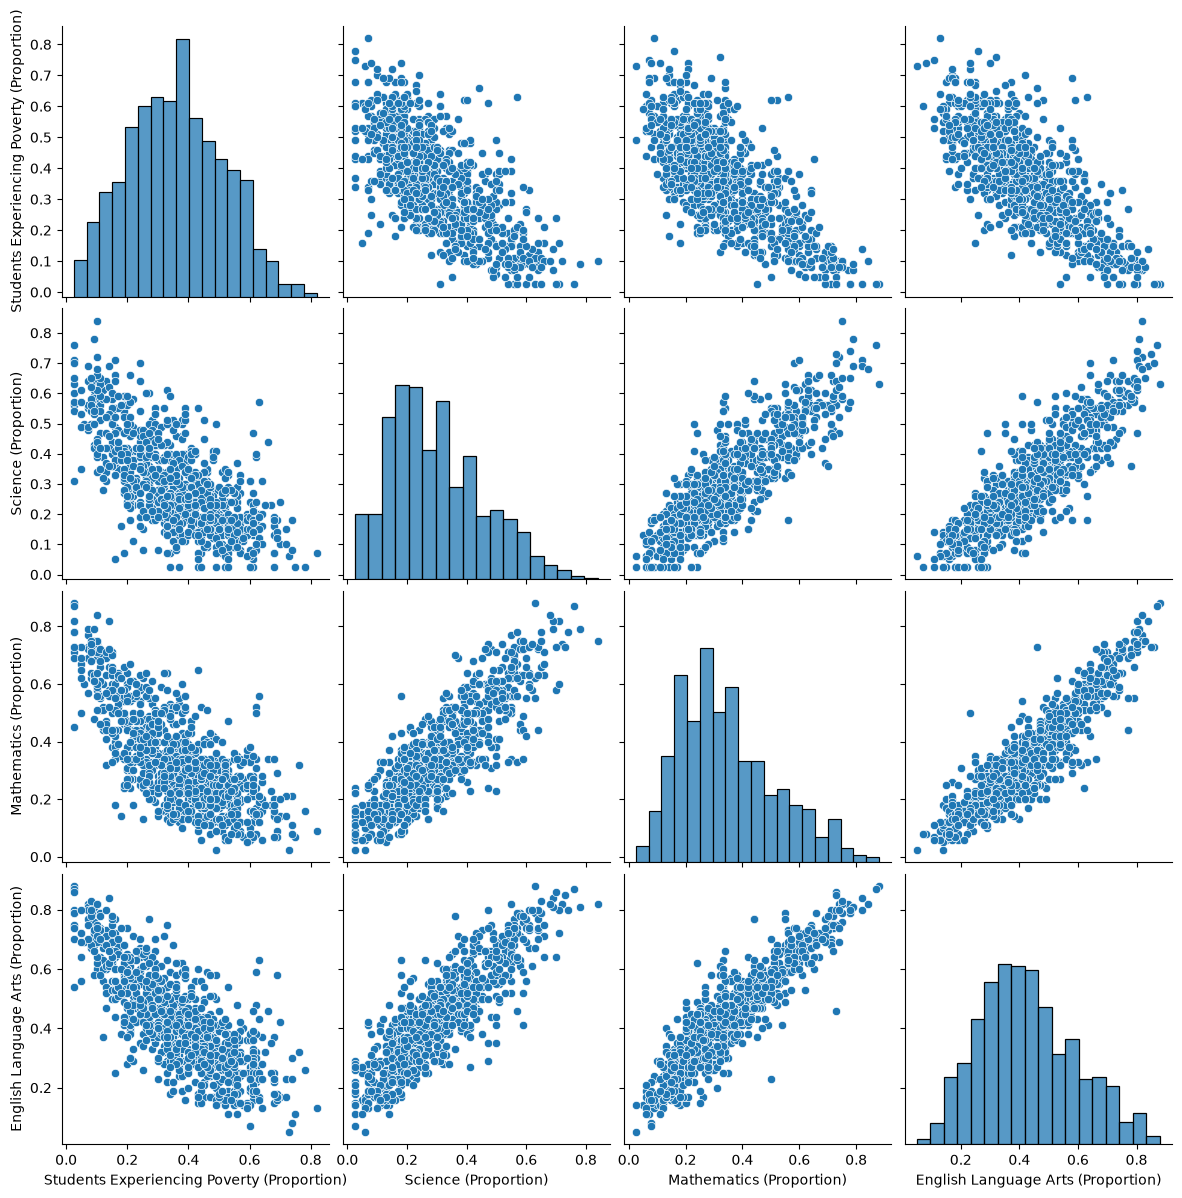

In [26]:
# Create scatter plots of the most strongly associated variables across the state.  
county_variables_of_interest = [
    "Students Experiencing Poverty (Proportion)",
    "Science (Proportion)", 
    "Mathematics (Proportion)",
    "English Language Arts (Proportion)"
]

fig = sns.pairplot(quantitative_cols[county_variables_of_interest], height=3)
fig.figure.savefig("output.png")

Multnomah County Scatter Plots 


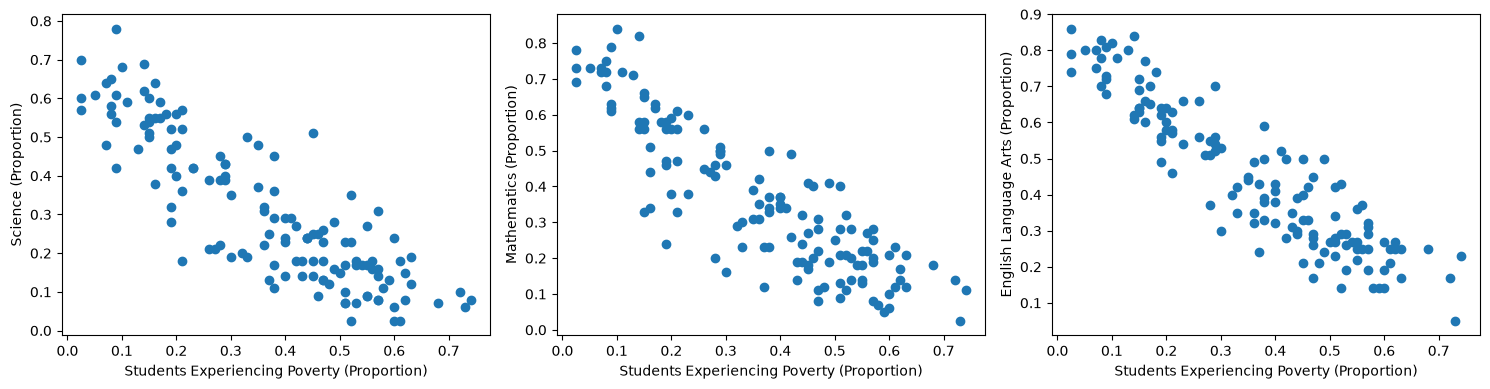

In [27]:
# Create scatter plots of the most strongly associated variables for a selected county in Oregon. 
col = "Multnomah"

col_data = school_data[school_data["County"] == col][county_variables_of_interest]
    
fig, axes = plt.subplots(1, 3, figsize=(15, 4)) 

print(f"{col} County Scatter Plots ")

axes[0].scatter(col_data["Students Experiencing Poverty (Proportion)"], col_data["Science (Proportion)"])
axes[0].set_xlabel("Students Experiencing Poverty (Proportion)")
axes[0].set_ylabel("Science (Proportion)")

axes[1].scatter(col_data["Students Experiencing Poverty (Proportion)"], col_data["Mathematics (Proportion)"])
axes[1].set_xlabel("Students Experiencing Poverty (Proportion)")
axes[1].set_ylabel("Mathematics (Proportion)")

axes[2].scatter(col_data["Students Experiencing Poverty (Proportion)"], col_data["English Language Arts (Proportion)"])
axes[2].set_xlabel("Students Experiencing Poverty (Proportion)")
axes[2].set_ylabel("English Language Arts (Proportion)")

plt.tight_layout()
plt.show()

    


**Impressions**

Based on my explatory data analysis, there is a lot of potential for applying effective inference and prediction to the dataset given the strong association amongst certain variables in the dataset. In general, meaning at both a county and nationwide scale, the Pearson Correlation Coefficient analysis revealed that the strongest linear associations in the data are found between proportion of students experiencing poverty at school and three other proportions: students who meet academic standards for math, science, and English language arts. Therefore, these four variables will likely be the main focus of the next to stages of the Data Science lifecycle. However, the county and grades variables may also be useful for a clustering analysis where a model predicts the county and/or grade level of each school based on certain other variable values.

**Inference**

Based on the correlation coefficients for the proportion of students experiencing poverty and the academic performance in math, science, and english, it is a reasonable question to ask is that if there is a real negative associations for all three relationships.

To answer this question, are three seperate null hypotheses: the model slope between poverty, and academic performance in math, science and english are equal to zero. The alternative hypotheses in this case are: the model slope between poverty, and academic performance in math, science and english are not equal to zero. To reject or accept these hypotheses, the statsmodel Ordinary Least Squares method is used to find the slope, and its 95% confidence interval and p-value.
 

In [28]:
# Drop rows that have don't have a value for every column of the features of interest.
subjects = ["Science (Proportion)", "Mathematics (Proportion)", "English Language Arts (Proportion)"]
poverty_subject_df = quantitative_cols[subjects + ["Students Experiencing Poverty (Proportion)"]].dropna(how="any").reset_index(drop=True)
poverty_subject_df

,Science (Proportion),Mathematics (Proportion),English Language Arts (Proportion),Students Experiencing Poverty (Proportion)
0,0.61,0.64,0.75,0.33
1,0.13,0.23,0.29,0.33
2,0.21,0.13,0.4,0.33
3,0.42,0.45,0.61,0.26
4,0.46,0.6,0.62,0.38
...,...,...,...,...
835,0.08,0.11,0.19,0.51
836,0.025,0.08,0.07,0.6
837,0.26,0.16,0.27,0.4
838,0.19,0.26,0.36,0.26


In [29]:
# Function to return a fit linear model for two features in a DataFrane
def fit_pair_model_stats(sample):
    x = sample.iloc[:, 1:2] # x = poverty
    x = sm.add_constant(x)
    y = sample.iloc[:, 0] # y = subject
    model = sm.OLS(y.astype(float), x.astype(float)).fit()
    return model

,Subject,Slope,P-Value,95% Confidence Interval
0,Science (Proportion),-0.664246,1.153312e-118,"[-0.7117921658916663, -0.6167008190019111]"
1,Mathematics (Proportion),-0.770433,2.113125e-139,"[-0.8196605779823344, -0.7212049051346517]"
2,English Language Arts (Proportion),-0.795324,1.695100e-173,"[-0.838447480432695, -0.7522001138259035]"


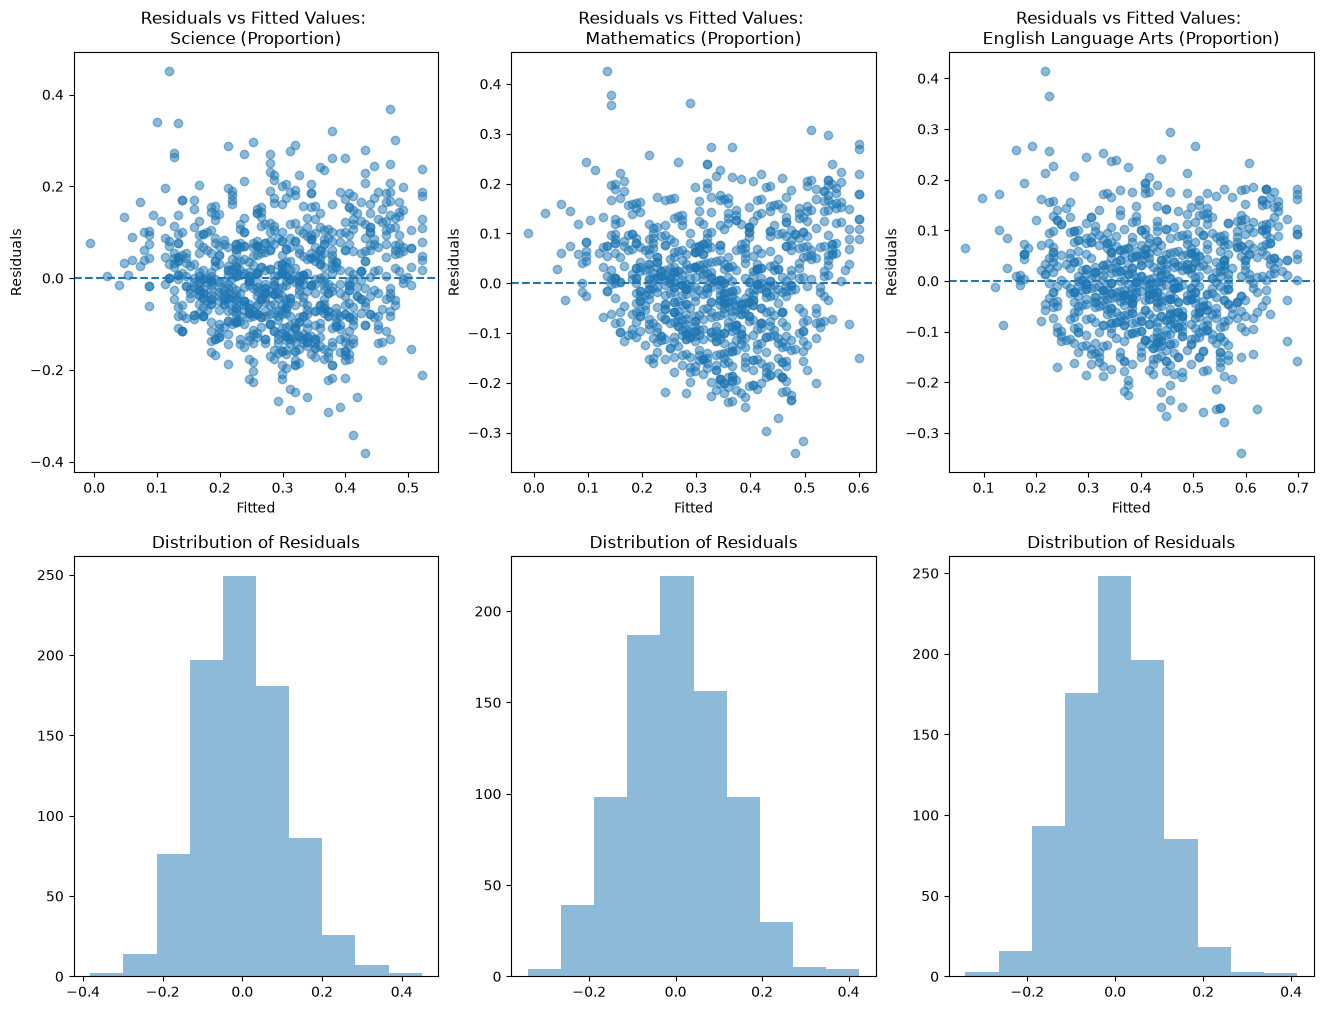

In [30]:
# Calculate and arrange slopes, and their corresponding 95% confidence interval and p-value into a DataFrame. Create residual plots of each fit model to assess normality of residuals. 
i = 0
stats_df = pd.DataFrame(columns=["Subject", "Slope", "P-Value", "95% Confidence Interval"])
fig, axes = plt.subplots(2, 3, figsize=(16, 12)) 
for variable in subjects:
    sample = poverty_subject_df[[variable, "Students Experiencing Poverty (Proportion)"]]
    subject_model = fit_pair_model_stats(sample)
    slope = subject_model.params.iloc[1] # slope 
    p_value = subject_model.pvalues.iloc[1] # p-value
    ci_95 = subject_model.conf_int().iloc[1].to_list() # 95% confidence interval
    stats_df.loc[i] = [variable, slope, p_value, ci_95]

    fitted = subject_model.fittedvalues
    residuals = subject_model.resid

    axes[0][i].scatter(fitted, residuals, alpha=0.5)
    axes[0][i].axhline(0, linestyle="--")
    axes[0][i].set_xlabel(f"Fitted")
    axes[0][i].set_ylabel("Residuals")
    axes[0][i].set_title(f"Residuals vs Fitted Values: \n {variable} ")

    axes[1][i].hist(residuals, alpha=0.5)
    axes[1][i].set_title(f"Distribution of Residuals")

    i += 1
stats_df

To begin, the residual plots and histogram verify that linear regression is an appropriate model to assess associations given the normal-like distribution of residuals for each relationship. With this, for each null hypothesis, the bounds of 95% confidence interval do not contain zero and p-value is extraordinarily close to zero. Therefore, there is strong evidence to reject all the null hypotheses, making it statistically significant that the slope of each modeled relationship is not equal to zero. In other words, with the evidence here, it is likely that with an increase of the proportion of students experiencing poverty at school, there is also a decrease in the proportion of student who meet academic standards for math, science, and English language arts.

**Prediction**

Because of the newfound significane in the association between poverty and academic peformance, the latter will be a target variable to model. Because both of these variables are numeric, a regression model is the best approach to predict the proportion of students experiencing poverty based on the proportion of students who met academic standards for math, science, and English language arts. To find the most appropriate model, i.e. that with the least error, two additional models other than simple linear regression will be used: multiple linear regression and non-linear regression (quadratic).

In [31]:
# Define predictor and predictions features, i.e. independent and dependent variables. Create a data table containing all of them with no Null values in any column. 
x_fields = [
    'Students Experiencing Poverty (Proportion)',
    'Regular Attenders (Proportion)',
    'Experienced Teachers (Proportion)',
    'Students with Disabilities (Proportion)',
    'Ever English Learners (Proportion)',
    'Average Teacher Retention Rate (Proportion)'
    ]
y_fields = [
    "Science (Proportion)", 
    "Mathematics (Proportion)",
    "English Language Arts (Proportion)"
    ]
predict_table = quantitative_cols[y_fields + x_fields].dropna(how="any").reset_index(drop=True)
predict_table

,Science (Proportion),Mathematics (Proportion),English Language Arts (Proportion),Students Experiencing Poverty (Proportion),Regular Attenders (Proportion),Experienced Teachers (Proportion),Students with Disabilities (Proportion),Ever English Learners (Proportion),Average Teacher Retention Rate (Proportion)
0,0.61,0.64,0.75,0.33,0.88,0.77,0.11,0.09,0.88
1,0.13,0.23,0.29,0.33,0.72,0.7,0.12,0.1,0.88
2,0.21,0.13,0.4,0.33,0.7,0.85,0.19,0.12,0.86
3,0.42,0.45,0.61,0.26,0.66,0.82,0.17,0.05,0.87
4,0.7,0.58,0.64,0.24,0.83,0.86,0.19,0.025,0.87
...,...,...,...,...,...,...,...,...,...
656,0.11,0.08,0.16,0.54,0.66,0.64,0.14,0.63,0.93
657,0.08,0.11,0.19,0.51,0.56,0.81,0.17,0.74,0.87
658,0.025,0.08,0.07,0.6,0.68,0.82,0.12,0.83,0.91
659,0.26,0.16,0.27,0.4,0.6,0.58,0.08,0.31,0.75


In [32]:
# Split up the data table into training and testing subsets. 
x_train, x_holdout, y_train, y_holdout = train_test_split(predict_table[x_fields], predict_table[y_fields], test_size=0.5)
xy_train = pd.concat([y_train, x_train], axis=1)
xy_holdout = pd.concat([y_holdout, x_holdout], axis=1)

In [33]:
# Calculate the training and holdout root mean square difference for every relationship model with varying numbers of features.
rmse_df = pd.DataFrame({"Feature Count": np.arange(1, len(x_fields) + 1)})
for output in y_fields:
    y_train = xy_train[output]
    y_holdout = xy_holdout[output]
    train_rmse_array = np.array([])
    holdout_rmse_array = np.array([])
    for n in range(len(x_fields)):
        x_train  = xy_train[x_fields].iloc[:, :n+1]
        x_holdout = xy_holdout[x_fields].iloc[:, :n+1]

        # Fit Model with Training Data
        model = LinearRegression()
        model.fit(x_train, y_train)

        # Training Error 
        y_hat_train = model.predict(x_train)
        rmse_train = np.sqrt(np.mean((y_train - y_hat_train)**2))
        train_rmse_array = np.append(train_rmse_array, rmse_train)

        # Holdout Error
        y_hat_holdout = model.predict(x_holdout)
        rmse_holdout = np.sqrt(np.mean((y_holdout - y_hat_holdout)**2))
        holdout_rmse_array = np.append(holdout_rmse_array, rmse_holdout)

    output_df = pd.DataFrame({f"{output} Training RMSE": train_rmse_array, f"{output} Holdout RMSE": holdout_rmse_array})
    rmse_df = pd.concat([rmse_df, output_df], axis=1)
rmse_df

,Feature Count,Science (Proportion) Training RMSE,Science (Proportion) Holdout RMSE,Mathematics (Proportion) Training RMSE,Mathematics (Proportion) Holdout RMSE,English Language Arts (Proportion) Training RMSE,English Language Arts (Proportion) Holdout RMSE
0,1,0.108628,0.103146,0.115327,0.110795,0.096427,0.097291
1,2,0.104717,0.098887,0.108347,0.099581,0.092135,0.090432
2,3,0.103823,0.098200,0.105334,0.098219,0.089538,0.092188
3,4,0.103640,0.098293,0.105007,0.097481,0.089077,0.092358
4,5,0.099688,0.096352,0.102145,0.096313,0.083371,0.087622
5,6,0.099687,0.096345,0.101981,0.096818,0.083351,0.087815


The number of features used to predict the proportion of students who met academic standards for math, science, and English language arts appears to have little effect on the overall error of the model. Therefore, a regression model between two variables: poverty and academic performamce is the most appropriate, as it reduces model complexity without losing overall accuracy.

Students Experiencing Poverty (Proportion) v. Science (Proportion) Training RMSE: 0.11119826268824277
Students Experiencing Poverty (Proportion) v. Science (Proportion) Holdout RMSE: 0.11290587148548856
Students Experiencing Poverty (Proportion) v. Mathematics (Proportion) Training RMSE: 0.11457280753423556
Students Experiencing Poverty (Proportion) v. Mathematics (Proportion) Holdout RMSE: 0.117000138605407
Students Experiencing Poverty (Proportion) v. English Language Arts (Proportion) Training RMSE: 0.10068437001704811
Students Experiencing Poverty (Proportion) v. English Language Arts (Proportion) Holdout RMSE: 0.10205138444673616


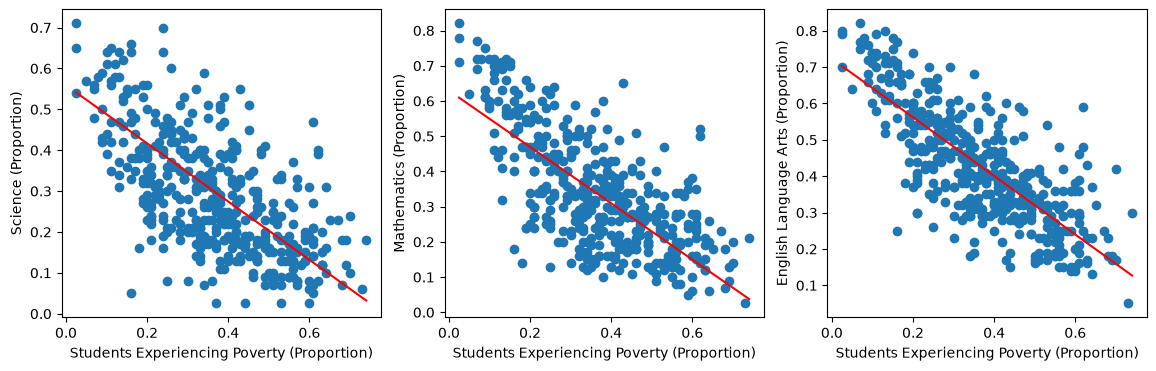

In [34]:
# Calculate the training and holdout root mean square difference for every linear relationship between proportion of student's experiencing poverty and proportion of students who met academic standards for math, science, and English language arts.
fig, axes = plt.subplots(1, 3, figsize=(14, 4)) 

x_train, x_holdout, y_train, y_holdout = train_test_split(poverty_subject_df["Students Experiencing Poverty (Proportion)"], poverty_subject_df[y_fields], test_size=0.5)
xy_train = pd.concat([y_train, x_train], axis=1)
xy_holdout = pd.concat([y_holdout, x_holdout], axis=1)

poverty_subject_df
i = 0
for subject in y_fields:
    x_train  = xy_train[['Students Experiencing Poverty (Proportion)']]
    x_holdout = xy_holdout[['Students Experiencing Poverty (Proportion)']]

    y_train = xy_train[subject]
    y_holdout = xy_holdout[subject]

    model = LinearRegression()
    model.fit(x_train, y_train)

    y_hat_train = model.predict(x_train)
    rmse_train = np.sqrt(np.mean((y_train - y_hat_train)**2))
    print(f"Students Experiencing Poverty (Proportion) v. {subject} Training RMSE: {rmse_train}")

    y_hat_holdout = model.predict(x_holdout)
    rmse_holdout = np.sqrt(np.mean((y_holdout - y_hat_holdout)**2))
    print(f"Students Experiencing Poverty (Proportion) v. {subject} Holdout RMSE: {rmse_holdout}")

    plot_df = pd.concat([x_holdout.reset_index(drop=True), pd.DataFrame({f"{subject} PREDICTION": y_hat_holdout})], axis=1).sort_values("Students Experiencing Poverty (Proportion)").reset_index(drop=True)

    axes[i].scatter(x_holdout["Students Experiencing Poverty (Proportion)"], y_holdout)
    axes[i].plot(plot_df["Students Experiencing Poverty (Proportion)"], plot_df[f"{subject} PREDICTION"], color = 'r')
    axes[i].set_xlabel("Students Experiencing Poverty (Proportion)")
    axes[i].set_ylabel(subject)
    
    i += 1

In [35]:
# Add a squared column for the proportions of students experiencing poverty in order to properly fit a quadratic model. 
poverty_subject_df_sq = poverty_subject_df.copy()
poverty_subject_df_sq["Students Experiencing Poverty (Proportion) SQUARED"] = poverty_subject_df["Students Experiencing Poverty (Proportion)"] ** 2
poverty_subject_df_sq

,Science (Proportion),Mathematics (Proportion),English Language Arts (Proportion),Students Experiencing Poverty (Proportion),Students Experiencing Poverty (Proportion) SQUARED
0,0.61,0.64,0.75,0.33,0.1089
1,0.13,0.23,0.29,0.33,0.1089
2,0.21,0.13,0.4,0.33,0.1089
3,0.42,0.45,0.61,0.26,0.0676
4,0.46,0.6,0.62,0.38,0.1444
...,...,...,...,...,...
835,0.08,0.11,0.19,0.51,0.2601
836,0.025,0.08,0.07,0.6,0.36
837,0.26,0.16,0.27,0.4,0.16
838,0.19,0.26,0.36,0.26,0.0676


Students Experiencing Poverty (Proportion) v. Science (Proportion) SQUARED Training RMSE: 0.10668350696919648
Students Experiencing Poverty (Proportion) v. Science (Proportion) SQUARED Holdout RMSE: 0.11042957196551055
Students Experiencing Poverty (Proportion) v. Mathematics (Proportion) SQUARED Training RMSE: 0.10960114900605178
Students Experiencing Poverty (Proportion) v. Mathematics (Proportion) SQUARED Holdout RMSE: 0.10740604104663634
Students Experiencing Poverty (Proportion) v. English Language Arts (Proportion) SQUARED Training RMSE: 0.10014124170488038
Students Experiencing Poverty (Proportion) v. English Language Arts (Proportion) SQUARED Holdout RMSE: 0.09480555830471112


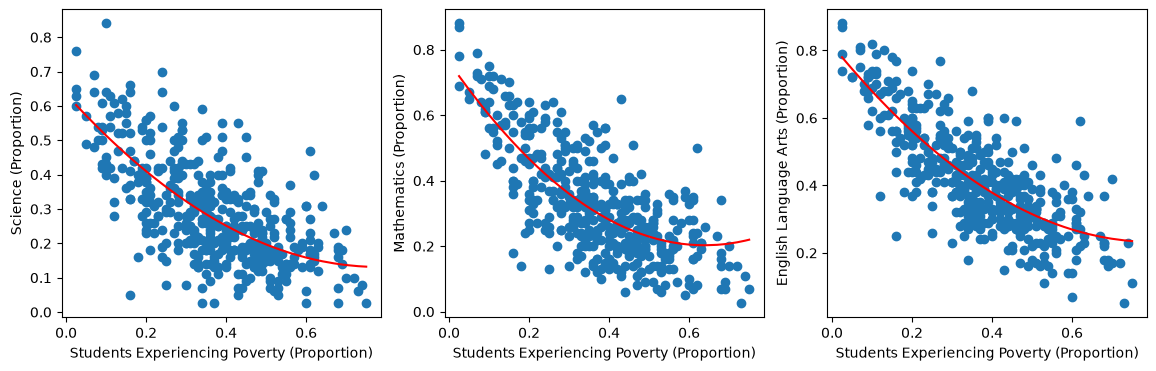

In [36]:
# Calculate the training and holdout root mean square difference for every quadratic relationship between proportion of student's experiencing poverty and proportion of students who met academic standards for math, science, and English language arts.
fig, axes = plt.subplots(1, 3, figsize=(14, 4)) 

x_train, x_holdout, y_train, y_holdout = train_test_split(poverty_subject_df_sq[["Students Experiencing Poverty (Proportion)", "Students Experiencing Poverty (Proportion) SQUARED"]], poverty_subject_df_sq[y_fields], test_size=0.5)
xy_train = pd.concat([y_train, x_train], axis=1)
xy_holdout = pd.concat([y_holdout, x_holdout], axis=1)

i = 0
for subject in y_fields:
    x_train  = xy_train[["Students Experiencing Poverty (Proportion)", "Students Experiencing Poverty (Proportion) SQUARED"]]
    x_holdout = xy_holdout[["Students Experiencing Poverty (Proportion)", "Students Experiencing Poverty (Proportion) SQUARED"]]

    y_train = xy_train[subject]
    y_holdout = xy_holdout[subject]

    model = LinearRegression()
    model.fit(x_train, y_train)

    y_hat_train = model.predict(x_train)
    rmse_train = np.sqrt(np.mean((y_train - y_hat_train)**2))
    print(f"Students Experiencing Poverty (Proportion) v. {subject} SQUARED Training RMSE: {rmse_train}")

    y_hat_holdout = model.predict(x_holdout)
    rmse_holdout = np.sqrt(np.mean((y_holdout - y_hat_holdout)**2))
    print(f"Students Experiencing Poverty (Proportion) v. {subject} SQUARED Holdout RMSE: {rmse_holdout}")

    plot_df = pd.concat([x_holdout.reset_index(drop=True), pd.DataFrame({f"{subject} PREDICTION": y_hat_holdout})], axis=1).sort_values("Students Experiencing Poverty (Proportion)").reset_index(drop=True)

    axes[i].scatter(x_holdout["Students Experiencing Poverty (Proportion)"], y_holdout)
    axes[i].plot(plot_df["Students Experiencing Poverty (Proportion)"], plot_df[f"{subject} PREDICTION"], color = 'r')
    axes[i].set_xlabel("Students Experiencing Poverty (Proportion)")
    axes[i].set_ylabel(subject)
    
    i += 1


Overall, the linear and quadratic models for predicting the proportion of students who met academic standards for math, science, and English language arts based on the proportion of students experiencing poverty have very similar loss values. For both types of models based on the proportion of students experiencing poverty, the predictions for the proportion of students who met academic standards for English language arts had the least root mean square error. For the other two academic performance variables, the two types of models had very similar loss values. Therefore, the value for the proportion of students experiencing poverty is most applicable for predicting the proportion of students who met academic standards English language arts, regardless if it is utilized in a linear or quadratic model.

In terms of the model's utility, the main use to make estimates for the general academic success of students based on how many are experiencing poverty. To put it simply, the model can be used for predict how many students are likely to not meet certain academic requirements based on the overall poverty-level of students at school. With this information, schools can not only determine if they need to allcoate resources to mitigate financial stress on students, but also to decide if better school-wide academic support is necessary. 

Based on the analysis, more features in the linear regression didn't appear to make the model signicantly any better, so the best thing to do to improve the model is to expand the original dataset. Either so it includes multiple states or fills in missing data in the original data set. While this may not increase the error of the model, it ultimately will point to the truth about the relationship between poverty and academic performance. 


